# Forecasting the WTI calendar spread

This notebook estimates one-month-ahead changes in the WTI futures calendar spread using OLS and evaluates the resulting forecasts and trading signals.


In [1]:
import json
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import (acorr_breusch_godfrey, breaks_cusumolsresid,
                                          het_arch, het_breuschpagan, het_white, linear_reset)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

DATA_FILE = "Oil Data.xlsx"
FIG_DIR, OUT_DIR = Path("figures"), Path("outputs")
FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

SEED = 20261022          # fixes the bootstrap draws
HAC_LAGS = 6             # Newey-West lags
FEATURES = ["spread", "inventory_growth"]
MAIN_MODEL, SIMPLE_MODEL = "Spread + inventories", "Spread only"
OLS_SPECS = {MAIN_MODEL: FEATURES, SIMPLE_MODEL: ["spread"]}

P = lambda s: pd.Period(s, "M")
VALID_START, VALID_END, TEST_START = P("2015-01"), P("2018-12"), P("2019-01")

# One chart style for every figure
BLUE, ORANGE, GREY, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#8a8f98", "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"], "font.size": 9,
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "legend.frameon": False,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
})
RESULTS = {}             # key numbers quoted in the report, saved at the end


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=220, bbox_inches="tight")
    plt.show()


def show(table, name=None, decimals=4):
    # Display a table and, if a name is given, save it to outputs/ as CSV.
    if name:
        table.to_csv(OUT_DIR / f"{name}.csv")
    display(table.round(decimals))

## 1. Data preparation and forecast design


### 1.1 Monthly data and validation
The `Industry_M` worksheet supplies monthly observations for `CL1`, `CL2`, and `Inventories` from December 1994 to June 2024. Validation covers duplicate and missing months, numeric and finite values, and positive inventory levels for the log transformation.

In [2]:
book = pd.ExcelFile(DATA_FILE)
industry = pd.read_excel(book, sheet_name="Industry_M")
industry.columns = industry.columns.astype(str).str.strip()
industry = industry[["Date", "CL1", "CL2", "Inventories"]].copy()

industry["Date"] = pd.to_datetime(industry["Date"], errors="raise")
industry["month"] = industry["Date"].dt.to_period("M")
if industry["month"].duplicated().any():
    raise ValueError("Duplicate months in Industry_M.")

monthly = industry.set_index("month").sort_index()[["CL1", "CL2", "Inventories"]]
for column in monthly.columns:
    monthly[column] = pd.to_numeric(monthly[column], errors="raise")
if monthly.isna().any().any() or not np.isfinite(monthly.to_numpy(float)).all():
    raise ValueError("Missing or non-finite values in CL1, CL2 or Inventories.")
if (monthly["Inventories"] <= 0).any():
    raise ValueError("Inventories must be positive to take logs.")
if not monthly.index.equals(pd.period_range(monthly.index.min(), monthly.index.max(), freq="M")):
    raise ValueError("There is a gap in the monthly data.")

print(f"Monthly observations: {len(monthly)}, {monthly.index.min()} to {monthly.index.max()}")
print("Duplicated months: 0 | gaps: 0 | missing values: 0 | observations removed: 0")
display(monthly.head(3))

Monthly observations: 355, 1994-12 to 2024-06
Duplicated months: 0 | gaps: 0 | missing values: 0 | observations removed: 0


,CL1,CL2,Inventories
month,,,
1994-12,17.76,17.71,904519
1995-01,18.39,18.24,898253
1995-02,18.49,18.35,896939


### 1.2 Variables and sample periods

Construct the current spread, next-month spread change, and two-month-lagged inventory growth, then define the estimation, validation, and historical evaluation periods.

In [3]:
f = monthly[["CL1", "CL2"]].copy()
f["spread"] = monthly["CL2"] - monthly["CL1"]
f["inventory_growth"] = 100 * np.log(monthly["Inventories"]).diff().shift(2)
f["target"] = f["spread"].shift(-1) - f["spread"]
f["target_month"] = f.index + 1

frame = f.dropna(subset=FEATURES + ["target"]).copy()   # one row per forecast origin t
early = frame[frame["target_month"] < VALID_START]       # targets up to Dec 2014
dev = frame[frame["target_month"] < TEST_START]          # targets up to Dec 2018
val_idx = frame.index[(frame["target_month"] >= VALID_START) & (frame["target_month"] <= VALID_END)]
test_idx = frame.index[frame["target_month"] >= TEST_START]
assert (len(frame), len(early), len(dev), len(val_idx), len(test_idx)) == (351, 237, 285, 48, 66)

spread_all = f["spread"]
print(f"Usable observations: {len(frame)} (forecast origins {frame.index[0]} to {frame.index[-1]})")
print(f"Estimation to 2014: {len(early)} | to 2018: {len(dev)} | validation forecasts: {len(val_idx)} | evaluation forecasts: {len(test_idx)}")
print(f"Spread: mean {spread_all.mean():.2f}, sd {spread_all.std():.2f}, min {spread_all.min():.2f} ({spread_all.idxmin()}), "
      f"max {spread_all.max():.2f} ({spread_all.idxmax()}), in contango {100 * (spread_all > 0).mean():.0f}% of months")

Usable observations: 351 (forecast origins 1995-03 to 2024-05)
Estimation to 2014: 237 | to 2018: 285 | validation forecasts: 48 | evaluation forecasts: 66
Spread: mean 0.11, sd 0.87, min -2.76 (2022-05), max 4.45 (2009-01), in contango 57% of months


### 1.3 Estimation and Forecasting Functions

Define the functions used to estimate OLS models, generate monthly forecasts, and calculate forecast accuracy.

In [4]:
def fit_ols(df, cols, hac=False):
    X = sm.add_constant(df[cols], has_constant="add")
    fit = sm.OLS(df["target"], X).fit()
    return fit.get_robustcov_results(cov_type="HAC", maxlags=HAC_LAGS) if hac else fit


def one_step_forecasts(df, model, origins, window=None):
    # model is a list of regressors, "zero" or "mean". window=None gives an expanding window.
    rows = []
    for origin in origins:
        pos = df.index.get_loc(origin)
        train = df.iloc[(max(0, pos - window) if window else 0):pos]
        assert train["target_month"].max() <= origin        # no look-ahead
        now = df.loc[origin]
        if model == "zero":
            pred = 0.0
        elif model == "mean":
            pred = float(train["target"].mean())
        else:
            b = fit_ols(train, model).params
            pred = float(b["const"] + sum(b[c] * now[c] for c in model))
        rows.append((origin + 1, float(now["target"]), pred))
    return pd.DataFrame(rows, columns=["target_month", "actual", "prediction"]).set_index("target_month")


def accuracy(panel, zero_panel=None):
    e = panel["actual"] - panel["prediction"]
    out = {"n": len(e), "RMSE": np.sqrt((e ** 2).mean()), "MAE": e.abs().mean()}
    if zero_panel is not None:
        e0 = zero_panel["actual"] - zero_panel["prediction"]
        out["R2 vs zero (%)"] = 100 * (1 - (e ** 2).sum() / (e0 ** 2).sum())
    out["Direction right (%)"] = (np.nan if (panel["prediction"] == 0).all()
                                  else 100 * (np.sign(panel["actual"]) == np.sign(panel["prediction"])).mean())
    return out


def hac_slope(y, x, lags=HAC_LAGS):
    # Slope and Newey-West t-ratio from a regression of y on a constant and x.
    r = sm.OLS(y, sm.add_constant(x)).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return float(r.params.iloc[1]), float(r.tvalues.iloc[1]), r

## 2. Exploratory Analysis

### 2.1 Spread History
Plot the month-end spread and mark the sample periods.

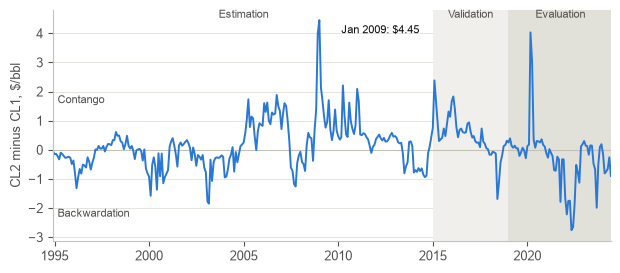

In [5]:
fig, ax = plt.subplots(figsize=(7.2, 3.0))
dates = spread_all.index.to_timestamp()
ax.axvspan(pd.Timestamp("2015-01-01"), pd.Timestamp("2018-12-31"), color="#f0efec", lw=0)
ax.axvspan(pd.Timestamp("2019-01-01"), pd.Timestamp("2024-06-30"), color="#e1e0d9", lw=0)
ax.axhline(0, color="#c3c2b7", lw=0.8)
ax.plot(dates, spread_all.values, color=BLUE, lw=1.4)
top = ax.get_ylim()[1]
ax.text(pd.Timestamp("2005-01-01"), top, "Estimation", ha="center", va="top", color=MUTED, fontsize=8)
ax.text(pd.Timestamp("2017-01-01"), top, "Validation", ha="center", va="top", color=MUTED, fontsize=8)
ax.text(pd.Timestamp("2021-10-01"), top, "Evaluation", ha="center", va="top", color=MUTED, fontsize=8)
ax.text(pd.Timestamp("1995-03-01"), 1.6, "Contango", color=MUTED, fontsize=8)
ax.text(pd.Timestamp("1995-03-01"), -2.3, "Backwardation", color=MUTED, fontsize=8)
ax.annotate("Jan 2009: $4.45", xy=(pd.Timestamp("2009-01-01"), 4.45), xytext=(pd.Timestamp("2010-03-01"), 4.1),
            fontsize=8, color=INK, va="center")
ax.set_ylabel("CL2 minus CL1, $/bbl")
ax.set_xlim(dates[0], dates[-1])
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
save(fig, "fig2_spread_history")

### 2.2 Stationarity and Unit Roots

Report ADF and KPSS tests for selected series and summarise preliminary in-sample fit.

In [6]:
def unit_root_row(series):
    series = series.dropna()
    a = adfuller(series, maxlag=12, regression="c", autolag="AIC")
    k = kpss(series, regression="c", nlags="auto")
    return {"n": len(series), "ADF stat": a[0], "ADF 5% cv": a[4]["5%"], "ADF p": a[1],
            "KPSS stat": k[0], "KPSS 5% cv": 0.463, "KPSS p (bounded 0.01-0.10)": k[1]}

ur = pd.DataFrame({
    "ln CL1, full sample": unit_root_row(np.log(monthly["CL1"])),
    "ln CL2, full sample": unit_root_row(np.log(monthly["CL2"])),
    "ln inventories, full sample": unit_root_row(np.log(monthly["Inventories"])),
    "Spread, full sample": unit_root_row(spread_all),
    "Spread, to 2018": unit_root_row(dev["spread"]),
    "Inventory growth, to 2018": unit_root_row(dev["inventory_growth"]),
    "Target (spread change), to 2018": unit_root_row(dev["target"]),
}).T
show(ur, "appendix_unit_roots", 3)

# How forecastable is each series from its own recent past?
flat = pd.DataFrame({"next": np.log(monthly["CL1"]).diff().shift(-1), "now": np.log(monthly["CL1"]).diff()}).dropna()
r2_flat = sm.OLS(flat["next"], sm.add_constant(flat["now"])).fit().rsquared
r2_spread = fit_ols(frame, ["spread"]).rsquared
print(f"R2, next month's CL1 return on this month's return: {r2_flat:.3f}")
print(f"R2, next month's spread change on this month's spread: {r2_spread:.3f}")
RESULTS.update(r2_flat_price=r2_flat, r2_spread_full=r2_spread)

,n,ADF stat,ADF 5% cv,ADF p,KPSS stat,KPSS 5% cv,KPSS p (bounded 0.01-0.10)
"ln CL1, full sample",355.0,-1.781,-2.870,0.390,1.826,0.463,0.010
"ln CL2, full sample",355.0,-2.017,-2.870,0.279,1.843,0.463,0.010
"ln inventories, full sample",355.0,-2.442,-2.870,0.130,1.298,0.463,0.010
"Spread, full sample",355.0,-4.457,-2.870,0.000,0.311,0.463,0.100
"Spread, to 2018",285.0,-5.354,-2.872,0.000,0.607,0.463,0.022
"Inventory growth, to 2018",285.0,-2.862,-2.872,0.050,0.093,0.463,0.100
"Target (spread change), to 2018",285.0,-11.297,-2.872,0.000,0.047,0.463,0.100


R2, next month's CL1 return on this month's return: 0.015
R2, next month's spread change on this month's spread: 0.102


### 2.3 Seasonality

Summarise spread changes by calendar month and test the monthly indicators jointly

In [7]:
by_month = dev.groupby(dev["target_month"].dt.month)["target"].agg(["mean", "std", "count"])
by_month.index = pd.to_datetime(by_month.index, format="%m").strftime("%b")
show(by_month.T, None, 2)

dummies = pd.get_dummies(dev["target_month"].dt.month, prefix="m", drop_first=True).astype(float)
dummies.index = dev.index
unrestricted = sm.OLS(dev["target"], sm.add_constant(pd.concat([dev[FEATURES], dummies], axis=1))).fit()
restricted = fit_ols(dev, FEATURES)
m, T, k = dummies.shape[1], len(dev), int(unrestricted.df_model) + 1
F_seas = (restricted.ssr - unrestricted.ssr) / unrestricted.ssr * (T - k) / m
p_seas = 1 - stats.f.cdf(F_seas, m, T - k)
print(f"F-test of 11 month dummies: F = {F_seas:.2f}, 5% critical value {stats.f.ppf(0.95, m, T - k):.2f}, p = {p_seas:.3f}")
RESULTS.update(seasonal_F=F_seas, seasonal_p=p_seas)

target_month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
mean,0.01,-0.03,-0.06,0.10,-0.16,-0.11,-0.04,0.08,-0.15,0.19,0.15,0.04
std,0.44,0.73,0.43,0.58,0.46,0.46,0.48,0.49,0.32,0.42,0.34,0.59
count,23.00,23.00,23.00,24.00,24.00,24.00,24.00,24.00,24.00,24.00,24.00,24.00


F-test of 11 month dummies: F = 1.08, 5% critical value 1.82, p = 0.378


### 2.4 Predictor Correlations

The correlations between the forecast target and the four candidate predictors are calculated using outcomes through December 2014.

,target,spread,inventory_growth,prev_change,ip_growth
target,1.000,-0.303,-0.113,-0.069,-0.053
spread,-0.303,1.000,0.165,0.302,-0.177
inventory_growth,-0.113,0.165,1.000,-0.028,-0.021
prev_change,-0.069,0.302,-0.028,1.000,0.066
ip_growth,-0.053,-0.177,-0.021,0.066,1.000


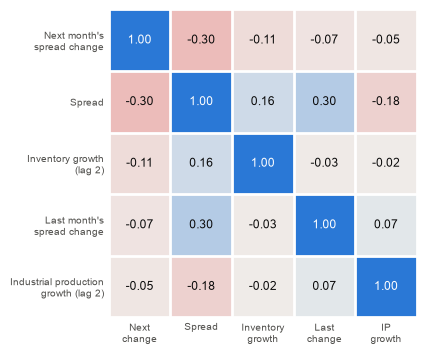

In [8]:
macro = pd.read_excel(book, sheet_name="Macro_M")
macro.columns = macro.columns.astype(str).str.strip()
macro["month"] = pd.to_datetime(macro["Date"]).dt.to_period("M")
ip = macro.set_index("month").sort_index()["IndustrialProduction Index"]

g = f.copy()
g["prev_change"] = g["spread"].diff()
g["ip_growth"] = (100 * np.log(ip).diff().shift(2)).reindex(g.index)
g = g.dropna(subset=["spread", "inventory_growth", "prev_change", "ip_growth", "target"])
g_early, g_dev = g[g["target_month"] < VALID_START], g[g["target_month"] < TEST_START]
assert len(g_early) == 237      # same rows as the main estimation sample

labels = {"target": "Next month's\nspread change", "spread": "Spread", "inventory_growth": "Inventory growth\n(lag 2)",
          "prev_change": "Last month's\nspread change", "ip_growth": "Industrial production\ngrowth (lag 2)"}
corr = g_early[list(labels)].corr()
show(corr, "appendix_correlations", 3)

cmap = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
fig, ax = plt.subplots(figsize=(5.2, 4.0))
ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(5)); ax.set_yticks(range(5))
short = ["Next\nchange", "Spread", "Inventory\ngrowth", "Last\nchange", "IP\ngrowth"]
ax.set_xticklabels(short, fontsize=7.5); ax.set_yticklabels(labels.values(), fontsize=7.5)
ax.tick_params(length=0); ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(5):
    for j in range(5):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if abs(v) > 0.6 else INK)
ax.set_xticks(np.arange(-0.5, 5), minor=True); ax.set_yticks(np.arange(-0.5, 5), minor=True)
ax.grid(which="minor", color="white", linewidth=2); ax.tick_params(which="minor", length=0)
save(fig, "figB1_correlation_matrix")
RESULTS["corr_with_target"] = corr["target"].drop("target").to_dict()
RESULTS["corr_spread_inventory"] = float(corr.loc["spread", "inventory_growth"])

## 3. Candidate Specifications

Candidate regressions are compared using in-sample fit and forecast accuracy.

In [9]:
candidates = {
    "Spread only": ["spread"],
    "Previous change only": ["prev_change"],
    "Spread + previous change": ["spread", "prev_change"],
    "Spread + inventory growth (main)": ["spread", "inventory_growth"],
    "Spread + IP growth": ["spread", "ip_growth"],
    "All four": ["spread", "prev_change", "inventory_growth", "ip_growth"],
}
rows = {}
for name, cols in candidates.items():
    fit = fit_ols(g_early, cols)
    rows[name] = {"Adj R2": fit.rsquared_adj, "AIC": fit.aic, "BIC": fit.bic,
                  "RMSE 2015-18": accuracy(one_step_forecasts(g, cols, val_idx))["RMSE"],
                  "RMSE 2019-24": accuracy(one_step_forecasts(g, cols, test_idx))["RMSE"],
                  "t of last variable": fit_ols(g_dev, cols, hac=True).tvalues[-1]}
cand_table = pd.DataFrame(rows).T
show(cand_table, "appendix_candidates", 4)

,Adj R2,AIC,BIC,RMSE 2015-18,RMSE 2019-24,t of last variable
Spread only,0.0880,323.0035,329.9396,0.4418,0.7538,-5.6556
Previous change only,0.0006,344.7067,351.6428,0.4663,0.8018,-0.6831
Spread + previous change,0.0847,324.8602,335.2643,0.4406,0.7545,0.4698
Spread + inventory growth (main),0.0882,323.9380,334.3422,0.4403,0.7536,-1.3239
Spread + IP growth,0.0959,321.9409,332.3451,0.4422,0.7609,-0.8815
All four,0.0932,324.6136,341.9539,0.4386,0.7604,-0.9001


## 4. Model Estimation and Forecasting

The spread-plus-inventories and spread-only OLS specifications are estimated and compared.

In [10]:
# Fit on data to 2014 (the sample used to compare specifications)
fit_table = pd.DataFrame({name: {"n": int(fit_ols(early, cols).nobs), "R2": fit_ols(early, cols).rsquared,
                                  "Adj R2": fit_ols(early, cols).rsquared_adj, "AIC": fit_ols(early, cols).aic,
                                  "BIC": fit_ols(early, cols).bic} for name, cols in OLS_SPECS.items()}).T
print("Fit on data to 2014")
show(fit_table, "appendix_fit_pre2015", 4)

# Table 1: estimates on data to 2018
main, main_hac = fit_ols(dev, FEATURES), fit_ols(dev, FEATURES, hac=True)
simple, simple_hac = fit_ols(dev, ["spread"]), fit_ols(dev, ["spread"], hac=True)
table1 = pd.DataFrame({
    "Main: coefficient": pd.Series(main_hac.params, index=["const"] + FEATURES),
    "Main: Newey-West t": pd.Series(main_hac.tvalues, index=["const"] + FEATURES),
    "Main: p": pd.Series(main_hac.pvalues, index=["const"] + FEATURES),
    "Main: ordinary t": main.tvalues,
    "Spread only: coefficient": pd.Series(simple_hac.params, index=["const", "spread"]),
    "Spread only: Newey-West t": pd.Series(simple_hac.tvalues, index=["const", "spread"]),
})
print(f"Table 1. Estimates on data to December 2018 (n = {int(main.nobs)})")
show(table1, "table1_estimates", 4)
print(f"R2: main {main.rsquared:.4f} (adjusted {main.rsquared_adj:.4f}); spread only {simple.rsquared:.4f}")

# F-test of gamma = 0 (lecture form): F = (RRSS - URSS)/URSS x (T - k)/m
T, k, m = int(main.nobs), 3, 1
F_gamma = (simple.ssr - main.ssr) / main.ssr * (T - k) / m
print(f"F-test of gamma = 0: RRSS {simple.ssr:.4f}, URSS {main.ssr:.4f}, F = {F_gamma:.2f}, "
      f"5% critical value F(1,{T - k}) = {stats.f.ppf(0.95, m, T - k):.2f}, p = {1 - stats.f.cdf(F_gamma, m, T - k):.3f}")

# Reading the coefficients
a, b, c = main.params["const"], main.params["spread"], main.params["inventory_growth"]
ig_mean, ig_sd, s_sd = dev["inventory_growth"].mean(), dev["inventory_growth"].std(), dev["spread"].std()
half_life = np.log(0.5) / np.log(1 + b)
long_run = -(a + c * ig_mean) / b
print(f"\nDickey-Fuller reading: ordinary t on the spread {main.tvalues['spread']:.2f} against a 5% critical value of -2.86")
print(f"Share of a gap closed each month: {-100 * b:.1f}% | half-life {half_life:.1f} months | long-run spread ${long_run:.2f}")
print(f"One-standard-deviation effect on the forecast: spread (sd {s_sd:.2f}) {abs(b) * s_sd:.3f} $/bbl; "
      f"inventory growth (sd {ig_sd:.2f} pct pts) {abs(c) * ig_sd:.3f} $/bbl")
for s_example in (1.0, -1.0):
    print(f"Spread of {s_example:+.2f}, inventory growth at its mean: forecast change {a + b * s_example + c * ig_mean:+.3f}")
RESULTS.update(table1={k_: {kk: float(vv) for kk, vv in v.items() if pd.notna(vv)} for k_, v in table1.to_dict().items()},
               r2_main=main.rsquared, r2_simple=simple.rsquared, F_gamma=F_gamma, half_life=half_life, long_run=long_run,
               one_sd_spread=abs(b) * s_sd, one_sd_inventory=abs(c) * ig_sd)

Fit on data to 2014


,n,R2,Adj R2,AIC,BIC
Spread + inventories,237.0,0.0960,0.0882,323.9380,334.3422
Spread only,237.0,0.0919,0.0880,323.0035,329.9396


Table 1. Estimates on data to December 2018 (n = 285)


,Main: coefficient,Main: Newey-West t,Main: p,Main: ordinary t,Spread only: coefficient,Spread only: Newey-West t
const,0.0386,1.4594,0.1456,1.3477,0.0384,1.4564
inventory_growth,-0.0317,-1.3239,0.1866,-1.2287,NaN,NaN
spread,-0.1762,-5.0971,0.0000,-5.0506,-0.1841,-5.6556


R2: main 0.0971 (adjusted 0.0907); spread only 0.0923
F-test of gamma = 0: RRSS 62.6215, URSS 62.2881, F = 1.51, 5% critical value F(1,282) = 3.87, p = 0.220

Dickey-Fuller reading: ordinary t on the spread -5.05 against a 5% critical value of -2.86
Share of a gap closed each month: 17.6% | half-life 3.6 months | long-run spread $0.21
One-standard-deviation effect on the forecast: spread (sd 0.81) 0.143 $/bbl; inventory growth (sd 1.10 pct pts) 0.035 $/bbl
Spread of +1.00, inventory growth at its mean: forecast change -0.139
Spread of -1.00, inventory growth at its mean: forecast change +0.213


## 5. Diagnostics and Stability

In [11]:
def diagnostics(df, cols):
    r = fit_ols(df, cols)
    X = r.model.exog
    out = {"Breusch-Godfrey (12 lags)": acorr_breusch_godfrey(r, nlags=12)[1],
           "Durbin-Watson (statistic)": durbin_watson(r.resid),
           "White": het_white(r.resid, X)[1],
           "Breusch-Pagan": het_breuschpagan(r.resid, X)[1],
           "ARCH-LM (6 lags)": het_arch(r.resid, nlags=6)[1],
           "Jarque-Bera": jarque_bera(r.resid)[1],
           "Residual kurtosis (statistic)": stats.kurtosis(r.resid) + 3,
           "RESET": float(linear_reset(r, power=3, use_f=False).pvalue),
           "CUSUM": breaks_cusumolsresid(r.resid, ddof=len(cols) + 1)[1]}
    if len(cols) > 1:
        out["VIF (statistic)"] = variance_inflation_factor(X, 1)
    return out

table2 = pd.DataFrame({name: diagnostics(dev, cols) for name, cols in OLS_SPECS.items()})
show(table2, "table2_diagnostics", 4)
RESULTS["table2"] = table2[MAIN_MODEL].to_dict()

,Spread + inventories,Spread only
Breusch-Godfrey (12 lags),0.7595,0.7649
Durbin-Watson (statistic),1.9557,1.9331
White,0.0002,0.0001
Breusch-Pagan,0.0181,0.0072
ARCH-LM (6 lags),0.0032,0.0050
Jarque-Bera,0.0000,0.0000
Residual kurtosis (statistic),8.8072,9.0181
RESET,0.0340,0.0123
CUSUM,0.0818,0.0663
VIF (statistic),1.0351,NaN


### 5.1 Structural Breaks and Subperiod Estimates
Coefficient stability is examined across selected break dates, subperiods, and spread regimes.

In [12]:
def chow(df, cols, break_month):
    full = fit_ols(df, cols)
    r1, r2 = fit_ols(df[df.index < P(break_month)], cols), fit_ols(df[df.index >= P(break_month)], cols)
    T, k = len(df), len(cols) + 1
    F = (full.ssr - (r1.ssr + r2.ssr)) / (r1.ssr + r2.ssr) * (T - 2 * k) / k
    return {"F": F, "5% critical value": stats.f.ppf(0.95, k, T - 2 * k), "p": 1 - stats.f.cdf(F, k, T - 2 * k)}

chow_table = pd.DataFrame({
    "July 2008 (data to 2018)": chow(dev, FEATURES, "2008-07"),
    "November 2014 (data to 2018)": chow(dev, FEATURES, "2014-11"),
    "March 2020 (full sample)": chow(frame, FEATURES, "2020-03"),
}).T
print("Chow tests, main model")
show(chow_table, "appendix_chow", 3)

sub = {}
for start, end in [("1995-03", "2004-12"), ("2005-01", "2014-12"), ("2015-01", "2024-05")]:
    r = fit_ols(frame.loc[start:end], FEATURES, hac=True)
    sub[f"{start} to {end}"] = {"n": int(r.nobs), "Spread": r.params[1], "t (spread)": r.tvalues[1],
                                "Inventory growth": r.params[2], "t (inventory)": r.tvalues[2]}
sub_table = pd.DataFrame(sub).T
print("Main model by sub-period (forecast origins)")
show(sub_table, "appendix_subperiods", 3)

# Is the response different in contango and backwardation? (follows up the RESET result)
asym = dev.assign(S_pos=dev["spread"].clip(lower=0), S_neg=dev["spread"].clip(upper=0))
ra = sm.OLS(asym["target"], sm.add_constant(asym[["S_pos", "S_neg", "inventory_growth"]])).fit(
    cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})
p_asym = float(ra.wald_test("S_pos = S_neg", scalar=True).pvalue)
print(f"Slope in contango {ra.params['S_pos']:.3f}, in backwardation {ra.params['S_neg']:.3f}, test of equal slopes p = {p_asym:.3f}")
RESULTS.update(chow=chow_table["p"].to_dict(), subperiod_spread=sub_table["Spread"].to_dict(),
               slope_contango=float(ra.params["S_pos"]), slope_backwardation=float(ra.params["S_neg"]), p_asym=p_asym)

Chow tests, main model


,F,5% critical value,p
July 2008 (data to 2018),1.082,2.637,0.357
November 2014 (data to 2018),0.267,2.637,0.849
March 2020 (full sample),4.742,2.631,0.003


Main model by sub-period (forecast origins)


,n,Spread,t (spread),Inventory growth,t (inventory)
1995-03 to 2004-12,118.0,-0.336,-4.114,-0.014,-0.626
2005-01 to 2014-12,120.0,-0.207,-3.232,-0.027,-0.516
2015-01 to 2024-05,113.0,-0.225,-2.841,-0.037,-1.522


Slope in contango -0.142, in backwardation -0.248, test of equal slopes p = 0.423


### 5.2 Recursive and rolling estimates

Coefficient estimates from expanding and 120-month rolling windows are plotted.

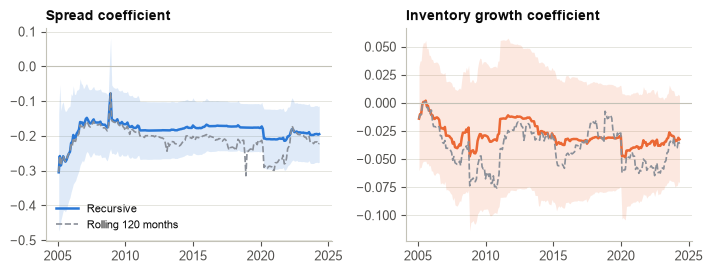

In [13]:
rec, roll = [], []
for pos in range(120, len(frame) + 1):
    r = fit_ols(frame.iloc[:pos], FEATURES, hac=True)
    rec.append((frame.index[pos - 1], r.params[1], r.bse[1], r.params[2], r.bse[2]))
    rr = fit_ols(frame.iloc[pos - 120:pos], FEATURES)
    roll.append((frame.index[pos - 1], rr.params["spread"], rr.params["inventory_growth"]))
rec = pd.DataFrame(rec, columns=["month", "b", "b_se", "c", "c_se"]).set_index("month")
roll = pd.DataFrame(roll, columns=["month", "b", "c"]).set_index("month")
x = rec.index.to_timestamp()

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8))
for ax, col, colour, title in [(axes[0], "b", BLUE, "Spread coefficient"), (axes[1], "c", ORANGE, "Inventory growth coefficient")]:
    ax.fill_between(x, rec[col] - 2 * rec[col + "_se"], rec[col] + 2 * rec[col + "_se"], color=colour, alpha=0.15, lw=0)
    ax.plot(x, rec[col], color=colour, lw=1.8, label="Recursive")
    ax.plot(x, roll[col], color=GREY, lw=1.2, ls="--", label="Rolling 120 months")
    ax.axhline(0, color="#c3c2b7", lw=0.8)
    ax.set_title(title)
    ax.xaxis.set_major_locator(mdates.YearLocator(5)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
save(fig, "figC1_coefficient_stability")

### 5.3 Fitted values and residuals

Observed changes, fitted values, and residuals are plotted through December 2018.

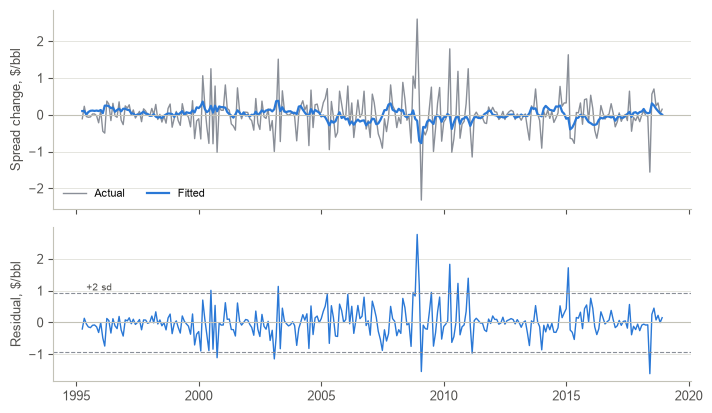

In [14]:
x = dev["target_month"].dt.to_timestamp()
fig, axes = plt.subplots(2, 1, figsize=(7.2, 4.2), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
axes[0].plot(x, dev["target"], color=GREY, lw=1.0, label="Actual")
axes[0].plot(x, main.fittedvalues, color=BLUE, lw=1.6, label="Fitted")
axes[0].axhline(0, color="#c3c2b7", lw=0.8)
axes[0].set_ylabel("Spread change, $/bbl"); axes[0].legend(loc="lower left", ncol=2, fontsize=8)
axes[1].plot(x, main.resid, color=BLUE, lw=1.0)
band = main.resid.std()
for level in (-2 * band, 2 * band):
    axes[1].axhline(level, color=GREY, lw=0.8, ls="--")
axes[1].axhline(0, color="#c3c2b7", lw=0.8)
axes[1].set_ylabel("Residual, $/bbl")
axes[1].text(x.iloc[2], 2 * band, "+2 sd", fontsize=7.5, color=MUTED, va="bottom")
axes[1].xaxis.set_major_locator(mdates.YearLocator(5)); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
save(fig, "figC2_actual_fitted_residual")

## 6. Forecasts and Benchmarks 

One-month-ahead forecasts from both OLS models are compared with zero-change and historical-mean benchmarks.

In [15]:
MODELS = {MAIN_MODEL: FEATURES, SIMPLE_MODEL: ["spread"], "Zero change": "zero", "Historical mean": "mean"}
VAL = {name: one_step_forecasts(frame, spec, val_idx) for name, spec in MODELS.items()}
TEST = {name: one_step_forecasts(frame, spec, test_idx) for name, spec in MODELS.items()}

val_table = pd.DataFrame({name: accuracy(p, VAL["Zero change"]) for name, p in VAL.items()}).T
test_table = pd.DataFrame({name: accuracy(p, TEST["Zero change"]) for name, p in TEST.items()}).T
table3 = pd.concat({"Validation 2015-18": val_table, "Evaluation 2019-Jun 2024": test_table}, axis=1)
show(table3, "table3_forecasts", 4)

cut = lambda panel, name: 100 * (1 - accuracy(panel[name])["RMSE"] / accuracy(panel["Zero change"])["RMSE"])
print(f"RMSE below zero change: main model {cut(VAL, MAIN_MODEL):.1f}% (validation), {cut(TEST, MAIN_MODEL):.1f}% (evaluation); "
      f"spread only {cut(VAL, SIMPLE_MODEL):.1f}%, {cut(TEST, SIMPLE_MODEL):.1f}%")
main_f, simple_f = TEST[MAIN_MODEL], TEST[SIMPLE_MODEL]
print(f"Evaluation: mean |forecast| {main_f['prediction'].abs().mean():.3f}, mean |actual| {main_f['actual'].abs().mean():.3f}")
for label, panel in [("validation", VAL), ("evaluation", TEST)]:
    print(f"Correlation of main and spread-only forecasts, {label}: {panel[MAIN_MODEL]['prediction'].corr(panel[SIMPLE_MODEL]['prediction']):.3f}")
RESULTS.update(table3={model: {f"{period} | {metric}": v for (period, metric), v in row.items()}
                       for model, row in table3.to_dict(orient="index").items()},
               rmse_cut_val=cut(VAL, MAIN_MODEL), rmse_cut_test=cut(TEST, MAIN_MODEL),
               mean_abs_forecast=main_f["prediction"].abs().mean(), mean_abs_actual=main_f["actual"].abs().mean())

Validation 2015-18                                                    Evaluation 2019-Jun 2024                                                   
                                      n    RMSE     MAE R2 vs zero (%) Direction right (%)                        n    RMSE     MAE R2 vs zero (%) Direction right (%)
Spread + inventories               48.0  0.4403  0.2834         9.4495             50.0000                     66.0  0.7536  0.4507        10.9298             53.0303
Spread only                        48.0  0.4418  0.2811         8.8284             52.0833                     66.0  0.7538  0.4399        10.8754             57.5758
Zero change                        48.0  0.4627  0.3100         0.0000                 NaN                     66.0  0.7985  0.4598         0.0000                 NaN
Historical mean                    48.0  0.4637  0.3107        -0.3996             43.7500                     66.0  0.7998  0.4610        -0.3199             34.8485

RMSE below zero change: main model 4.8% (validation), 5.6% (evaluation); spread only 4.5%, 5.6%
Evaluation: mean |forecast| 0.166, mean |actual| 0.460
Correlation of main and spread-only forecasts, validation: 0.950
Correlation of main and spread-only forecasts, evaluation: 0.950


### 6.1 Forecast Ranges and Coverage

Nominal forecast ranges are constructed and their observed coverage is reported.

In [16]:
def range_forecasts(df, cols, origins):
    rows = []
    for origin in origins:
        train = df.iloc[:df.index.get_loc(origin)]
        fit = fit_ols(train, cols)
        now = df.loc[origin]
        pred = float(fit.params["const"] + sum(fit.params[c] * now[c] for c in cols))
        rows.append((origin + 1, float(now["target"]), pred, np.sqrt(fit.mse_resid), fit.resid.iloc[-12:].std()))
    return pd.DataFrame(rows, columns=["target_month", "actual", "prediction", "s", "s_recent"]).set_index("target_month")

dens = range_forecasts(frame, FEATURES, val_idx.append(test_idx))
assert np.allclose(dens["prediction"], pd.concat([VAL[MAIN_MODEL], TEST[MAIN_MODEL]])["prediction"])
dens["p_up"] = stats.norm.cdf(dens["prediction"] / dens["s"])
err = (dens["actual"] - dens["prediction"]).abs()
cover = {}
for level in (0.50, 0.90):
    z = stats.norm.ppf(0.5 + level / 2)
    cover[f"{level:.0%} range"] = {"Constant, all": 100 * (err <= z * dens["s"]).mean(),
                                  "Constant, 2015-18": 100 * (err <= z * dens["s"])[:48].mean(),
                                  "Constant, 2019-24": 100 * (err <= z * dens["s"])[48:].mean(),
                                  "Recent volatility, all": 100 * (err <= z * dens["s_recent"]).mean(),
                                  "Recent volatility, 2015-18": 100 * (err <= z * dens["s_recent"])[:48].mean(),
                                  "Recent volatility, 2019-24": 100 * (err <= z * dens["s_recent"])[48:].mean()}
cover_table = pd.DataFrame(cover)
print("Share of outcomes inside the range (%), 114 out-of-sample months")
show(cover_table, "appendix_range_coverage", 1)
print(f"Residual standard error: {dens['s'].iloc[0]:.3f} at the first forecast, {dens['s'].iloc[-1]:.3f} at the last")

confident = dens[(dens["p_up"] > 0.6) | (dens["p_up"] < 0.4)]
right = np.sign(confident["prediction"]) == np.sign(confident["actual"])
print(f"Months with P(up) above 60% or below 40%: {len(confident)} of {len(dens)}; direction right in {100 * right.mean():.0f}% of them")
RESULTS.update(coverage=cover_table.to_dict(), confident_months=len(confident), confident_right=100 * right.mean(),
               s_last=dens["s"].iloc[-1])

Share of outcomes inside the range (%), 114 out-of-sample months


,50% range,90% range
"Constant, all",65.8,88.6
"Constant, 2015-18",70.8,95.8
"Constant, 2019-24",62.1,83.3
"Recent volatility, all",64.9,86.8
"Recent volatility, 2015-18",64.6,91.7
"Recent volatility, 2019-24",65.2,83.3


Residual standard error: 0.476 at the first forecast, 0.533 at the last
Months with P(up) above 60% or below 40%: 42 of 114; direction right in 71% of them


### 6.2 Observed and forecast spread changes
Observed changes, point forecasts, and nominal 90% ranges are plotted for January 2015 to June 2024.

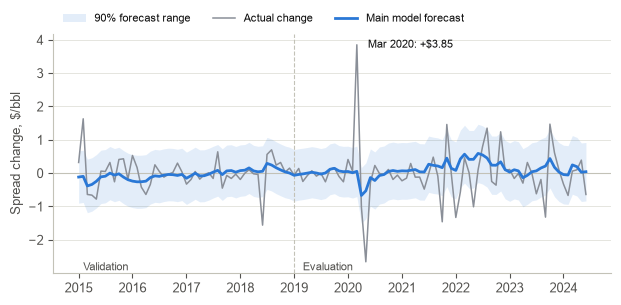

March to June 2020 share of evaluation squared error: 50.9%
March 2020: actual +3.85, forecast +0.053


In [17]:
both = pd.concat([VAL[MAIN_MODEL], TEST[MAIN_MODEL]])
x = both.index.to_timestamp()
fig, ax = plt.subplots(figsize=(7.2, 3.1))
ax.axhline(0, color="#c3c2b7", lw=0.8)
ax.axvline(pd.Timestamp("2019-01-01"), color="#c3c2b7", lw=0.8, ls="--")
z90 = stats.norm.ppf(0.95)
ax.fill_between(x, dens["prediction"] - z90 * dens["s"], dens["prediction"] + z90 * dens["s"], color=BLUE, alpha=0.13, lw=0,
                label="90% forecast range")
ax.plot(x, both["actual"], color=GREY, lw=1.1, label="Actual change")
ax.plot(x, both["prediction"], color=BLUE, lw=2.0, label="Main model forecast")
ax.set_ylabel("Spread change, $/bbl")
low = ax.get_ylim()[0]
ax.text(pd.Timestamp("2015-02-01"), low, "Validation", color=MUTED, fontsize=8, va="bottom")
ax.text(pd.Timestamp("2019-03-01"), low, "Evaluation", color=MUTED, fontsize=8, va="bottom")
money = lambda v: ("+" if v >= 0 else "−") + f"${abs(v):.2f}"
v = both.loc[P("2020-03"), "actual"]
ax.text(pd.Timestamp("2020-05-15"), v, f"Mar 2020: {money(v)}", fontsize=8, va="center")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, fontsize=8)
ax.xaxis.set_major_locator(mdates.YearLocator(1)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
save(fig, "fig3_actual_vs_forecast")

sq = (main_f["actual"] - main_f["prediction"]) ** 2
crash = (main_f.index >= P("2020-03")) & (main_f.index <= P("2020-06"))
print(f"March to June 2020 share of evaluation squared error: {100 * sq[crash].sum() / sq.sum():.1f}%")
print(f"March 2020: actual {main_f.loc[P('2020-03'), 'actual']:+.2f}, forecast {main_f.loc[P('2020-03'), 'prediction']:+.3f}")
RESULTS.update(crash_share=100 * sq[crash].sum() / sq.sum(), mar2020_actual=main_f.loc[P("2020-03"), "actual"],
               mar2020_forecast=main_f.loc[P("2020-03"), "prediction"])

### 6.3 Forecast contributions
The final 24 forecasts are decomposed into intercept, spread, and inventory contributions.

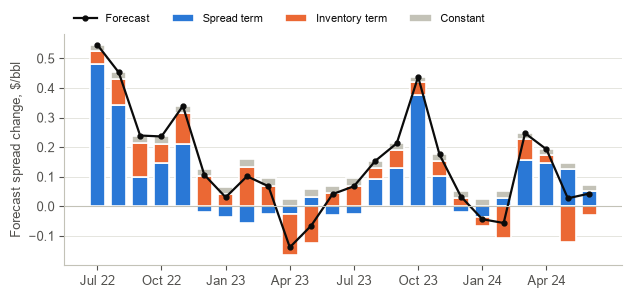

Average size over 2019-24: spread term 0.120, inventory term 0.057 $/bbl (spread share 68%)


In [18]:
parts = []
for origin in test_idx:
    train = frame.iloc[:frame.index.get_loc(origin)]
    b = fit_ols(train, FEATURES).params
    now = frame.loc[origin]
    parts.append((origin + 1, b["const"], b["spread"] * now["spread"], b["inventory_growth"] * now["inventory_growth"]))
parts = pd.DataFrame(parts, columns=["target_month", "Constant", "Spread term", "Inventory term"]).set_index("target_month")
assert np.allclose(parts.sum(axis=1), TEST[MAIN_MODEL]["prediction"])
parts.to_csv(OUT_DIR / "forecast_contributions.csv")

last = parts.iloc[-24:]
x = np.arange(len(last))
fig, ax = plt.subplots(figsize=(7.2, 3.0))
pos_base, neg_base = np.zeros(len(last)), np.zeros(len(last))
for col, colour in [("Spread term", BLUE), ("Inventory term", ORANGE), ("Constant", "#c3c2b7")]:
    v = last[col].values
    base = np.where(v >= 0, pos_base, neg_base)
    ax.bar(x, v, bottom=base, width=0.72, color=colour, edgecolor="white", linewidth=1.2, label=col)
    pos_base, neg_base = pos_base + np.clip(v, 0, None), neg_base + np.clip(v, None, 0)
ax.plot(x, last.sum(axis=1).values, color=INK, lw=1.6, marker="o", ms=3.5, label="Forecast")
ax.axhline(0, color="#c3c2b7", lw=0.8)
ax.set_xticks(x[::3]); ax.set_xticklabels([m.strftime("%b %y") for m in last.index[::3].to_timestamp()])
ax.set_ylabel("Forecast spread change, $/bbl")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4, fontsize=8)
save(fig, "fig4_forecast_contributions")

share = parts["Spread term"].abs().mean() / (parts["Spread term"].abs().mean() + parts["Inventory term"].abs().mean())
print(f"Average size over 2019-24: spread term {parts['Spread term'].abs().mean():.3f}, inventory term {parts['Inventory term'].abs().mean():.3f} $/bbl "
      f"(spread share {100 * share:.0f}%)")
RESULTS.update(mean_abs_spread_term=parts["Spread term"].abs().mean(), mean_abs_inventory_term=parts["Inventory term"].abs().mean())

### 6.4 July 2024 forecast
The model is refitted through June 2024 to produce a forecast for July 2024.

In [19]:
latest = fit_ols(frame, FEATURES)
S_now = float(spread_all.iloc[-1])
IG_now = float((100 * np.log(monthly["Inventories"]).diff().shift(2)).iloc[-1])
terms = {"Constant": latest.params["const"], "Spread term": latest.params["spread"] * S_now,
         "Inventory term": latest.params["inventory_growth"] * IG_now}
forecast_now = sum(terms.values())
print(f"Equation on {int(latest.nobs)} months: dS = {latest.params['const']:.4f} + ({latest.params['spread']:.4f}) S + ({latest.params['inventory_growth']:.4f}) IG")
print(f"{spread_all.index[-1]}: spread {S_now:.2f}, inventory growth two months earlier {IG_now:+.2f}%")
print("  " + " | ".join(f"{k_} {v:+.3f}" for k_, v in terms.items()))
print(f"Forecast change for {spread_all.index[-1] + 1}: {forecast_now:+.3f}, implied spread {S_now + forecast_now:.2f}")
s_now = float(np.sqrt(latest.mse_resid))
low, high = forecast_now - z90 * s_now, forecast_now + z90 * s_now
p_up = float(stats.norm.cdf(forecast_now / s_now))
print(f"Residual standard error {s_now:.3f}: 90% range {low:+.2f} to {high:+.2f}, probability the spread rises {100 * p_up:.0f}%")
RESULTS.update(latest_spread=S_now, latest_ig=IG_now, latest_forecast=forecast_now, latest_terms=terms,
               latest_s=s_now, latest_low=low, latest_high=high, latest_p_up=p_up)

Equation on 351 months: dS = 0.0190 + (-0.1950) S + (-0.0325) IG
2024-06: spread -0.90, inventory growth two months earlier +1.47%
  Constant +0.019 | Spread term +0.175 | Inventory term -0.048
Forecast change for 2024-07: +0.147, implied spread -0.75
Residual standard error 0.534: 90% range -0.73 to +1.02, probability the spread rises 61%


## 7. Forecast Evaluation and Robustness

Clark–West tests and paired block bootstrap intervals are used to assess differences in forecast accuracy.

In [20]:
def clark_west(actual, f_small, f_big):
    adj = (actual - f_small) ** 2 - ((actual - f_big) ** 2 - (f_small - f_big) ** 2)
    r = sm.OLS(adj.values, np.ones(len(adj))).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    return {"t": float(r.tvalues[0]), "p (one-sided)": float(1 - stats.norm.cdf(r.tvalues[0]))}


def bootstrap_gain(reference, candidate, seed, block=6, reps=2000):
    a = reference["actual"].to_numpy(float)
    d = (a - reference["prediction"].to_numpy(float)) ** 2 - (a - candidate["prediction"].to_numpy(float)) ** 2
    n, rng, means = len(d), np.random.default_rng(seed), np.empty(reps)
    for j in range(reps):
        starts = rng.integers(0, n, size=int(np.ceil(n / block)))
        idx = np.concatenate([(s + np.arange(block)) % n for s in starts])[:n]
        means[j] = d[idx].mean()
    low, high = np.quantile(means, [0.025, 0.975])
    return {"Mean gain": d.mean(), "95% low": low, "95% high": high, "Includes zero": bool(low <= 0 <= high)}


cw = {}
for label, panel in [("validation", VAL), ("evaluation", TEST)]:
    actual = panel["Zero change"]["actual"]
    cw[f"Main vs zero change, {label}"] = clark_west(actual, panel["Zero change"]["prediction"], panel[MAIN_MODEL]["prediction"])
    cw[f"Spread only vs zero change, {label}"] = clark_west(actual, panel["Zero change"]["prediction"], panel[SIMPLE_MODEL]["prediction"])
    cw[f"Main vs spread only, {label}"] = clark_west(actual, panel[SIMPLE_MODEL]["prediction"], panel[MAIN_MODEL]["prediction"])
cw_table = pd.DataFrame(cw).T
print("Clark-West tests")
show(cw_table, "appendix_clark_west", 3)

boot = pd.DataFrame({
    "Spread only -> main, validation": bootstrap_gain(VAL[SIMPLE_MODEL], VAL[MAIN_MODEL], SEED),
    "Zero change -> main, validation": bootstrap_gain(VAL["Zero change"], VAL[MAIN_MODEL], SEED + 1),
    "Zero change -> main, evaluation": bootstrap_gain(TEST["Zero change"], TEST[MAIN_MODEL], SEED + 2),
    "Spread only -> main, evaluation": bootstrap_gain(TEST[SIMPLE_MODEL], TEST[MAIN_MODEL], SEED + 5),
}).T
print("Bootstrap of the squared-error gain, ($/bbl) squared")
show(boot, "appendix_bootstrap", 5)
RESULTS.update(clark_west=cw_table["p (one-sided)"].to_dict())

Clark-West tests


,t,p (one-sided)
"Main vs zero change, validation",1.739,0.041
"Spread only vs zero change, validation",1.768,0.039
"Main vs spread only, validation",0.833,0.202
"Main vs zero change, evaluation",1.893,0.029
"Spread only vs zero change, evaluation",1.842,0.033
"Main vs spread only, evaluation",0.632,0.264


Bootstrap of the squared-error gain, ($/bbl) squared


,Mean gain,95% low,95% high,Includes zero
"Spread only -> main, validation",0.00133,-0.004923,0.008187,True
"Zero change -> main, validation",0.020234,-0.012939,0.056021,True
"Zero change -> main, evaluation",0.069687,-0.0286,0.195053,True
"Spread only -> main, evaluation",0.000347,-0.013472,0.015242,True


### 7.1 Sensitivity Analysis

Forecast accuracy is compared across estimation windows, inventory lags, and the exclusion of March - June 2020 from scoring.

In [21]:
keep = ~crash
rob = {
    "Main, expanding window": accuracy(TEST[MAIN_MODEL], TEST["Zero change"]),
    "Main, rolling 120-month window": accuracy(one_step_forecasts(frame, FEATURES, test_idx, window=120), TEST["Zero change"]),
    "Spread only, rolling 120-month window": accuracy(one_step_forecasts(frame, ["spread"], test_idx, window=120), TEST["Zero change"]),
    "Main, without Mar-Jun 2020": accuracy(TEST[MAIN_MODEL][keep], TEST["Zero change"][keep]),
    "Spread only, without Mar-Jun 2020": accuracy(TEST[SIMPLE_MODEL][keep], TEST["Zero change"][keep]),
    "Zero change, without Mar-Jun 2020": accuracy(TEST["Zero change"][keep]),
}
rob_table = pd.DataFrame(rob).T
print("Evaluation period, 2019 to June 2024")
show(rob_table, "appendix_robustness", 4)
cut_ex = 100 * (1 - rob["Main, without Mar-Jun 2020"]["RMSE"] / rob["Zero change, without Mar-Jun 2020"]["RMSE"])
print(f"Main model RMSE below zero change without March to June 2020: {cut_ex:.1f}%")

# Inventory lag: 0 to 3 months
inv_growth = 100 * np.log(monthly["Inventories"]).diff()
lag_rows = {}
for lag in range(4):
    alt = f.copy()
    alt["inventory_growth"] = inv_growth.shift(lag)
    alt = alt.dropna(subset=FEATURES + ["target"])
    alt = alt.loc[alt.index.intersection(frame.index)]      # same months as the main model (lag 3 loses the first)
    alt_dev = alt[alt["target_month"] < TEST_START]
    lag_rows[f"Lag {lag}"] = {"t (inventory, to 2018)": fit_ols(alt_dev, FEATURES, hac=True).tvalues[2],
                              "RMSE 2015-18": accuracy(one_step_forecasts(alt, FEATURES, val_idx))["RMSE"],
                              "RMSE 2019-24": accuracy(one_step_forecasts(alt, FEATURES, test_idx))["RMSE"]}
lag_table = pd.DataFrame(lag_rows).T
print("Inventory growth at different lags (lag 2 is the main model)")
show(lag_table, "appendix_inventory_lags", 4)
RESULTS.update(rmse_cut_ex2020=cut_ex)

Evaluation period, 2019 to June 2024


,n,RMSE,MAE,R2 vs zero (%),Direction right (%)
"Main, expanding window",66.0,0.7536,0.4507,10.9298,53.0303
"Main, rolling 120-month window",66.0,0.7551,0.4609,10.5647,51.5152
"Spread only, rolling 120-month window",66.0,0.7524,0.4457,11.2025,54.5455
"Main, without Mar-Jun 2020",62.0,0.5446,0.3762,3.5433,50.0000
"Spread only, without Mar-Jun 2020",62.0,0.5386,0.3625,5.6680,54.8387
"Zero change, without Mar-Jun 2020",62.0,0.5545,0.3635,NaN,NaN


Main model RMSE below zero change without March to June 2020: 1.8%
Inventory growth at different lags (lag 2 is the main model)


,"t (inventory, to 2018)",RMSE 2015-18,RMSE 2019-24
Lag 0,0.1834,0.4439,0.7549
Lag 1,-0.1744,0.4439,0.7550
Lag 2,-1.3239,0.4403,0.7536
Lag 3,-1.3092,0.4528,0.7571


### 7.2 Commercial inventories

Monthly and weekly inventory measures are compared, and a lagged commercial stock measure is evaluated as an alternative predictor.

In [22]:
weekly = pd.read_excel(book, sheet_name="Industry_W")
weekly.columns = weekly.columns.astype(str).str.strip()
weekly = weekly.sort_values("Date").set_index("Date")
weekly_change = weekly["Weekly change in Crude Stock"]      # thousand barrels, commercial
inventories = monthly["Inventories"]                         # thousand barrels

spr_rows = {}
for year in ["2011", "2020", "2022"]:
    spr_rows[year] = {"Change in monthly Inventories (m bbl)": (inventories[f"{year}-12"] - inventories[f"{int(year) - 1}-12"]) / 1000,
                      "Sum of weekly commercial changes (m bbl)": weekly_change[year].sum() / 1000}
spr_table = pd.DataFrame(spr_rows).T
show(spr_table, "appendix_spr_check", 1)

commercial = weekly_change.fillna(0).cumsum() / 1000                      # million barrels, up to a constant
commercial_m = commercial.groupby(commercial.index.to_period("M")).last()
vs_norm = commercial_m - sum(commercial_m.shift(12 * j) for j in range(1, 6)) / 5
z = pd.DataFrame({"spread": spread_all, "stocks_vs_norm": vs_norm}).dropna()
slope, t_stat, reg = hac_slope(z["spread"], z["stocks_vs_norm"], lags=12)
print(f"Same month: spread on commercial stocks vs five-year norm: {slope:.4f} $/bbl per million barrels "
      f"(t = {t_stat:.2f}, R2 = {reg.rsquared:.2f}, n = {len(z)}); 50 million barrels = {50 * slope:.2f} $/bbl")

# The commercial measure as a predictor in place of inventory growth (lagged one month)
alt = frame.assign(stocks_vs_norm_l1=vs_norm.shift(1).reindex(frame.index)).dropna(subset=["stocks_vs_norm_l1"])
cols = ["spread", "stocks_vs_norm_l1"]
print(f"Spread + commercial stocks vs norm (lag 1): t = {fit_ols(alt[alt['target_month'] < TEST_START], cols, hac=True).tvalues[2]:.2f}, "
      f"RMSE 2015-18 {accuracy(one_step_forecasts(alt, cols, val_idx))['RMSE']:.4f}, "
      f"RMSE 2019-24 {accuracy(one_step_forecasts(alt, cols, test_idx))['RMSE']:.4f}")
RESULTS.update(same_month_slope=slope, same_month_t=t_stat, same_month_r2=reg.rsquared, spr_check=spr_table.to_dict())

,Change in monthly Inventories (m bbl),Sum of weekly commercial changes (m bbl)
2011,-37.3,-5.6
2020,66.7,63.6
2022,-218.5,2.8


Same month: spread on commercial stocks vs five-year norm: 0.0116 $/bbl per million barrels (t = 4.64, R2 = 0.31, n = 354); 50 million barrels = 0.58 $/bbl
Spread + commercial stocks vs norm (lag 1): t = 1.76, RMSE 2015-18 0.4521, RMSE 2019-24 0.7450


## 8. Spread Changes Around Contract Expiry

Daily spread changes are grouped around estimated expiry dates to examine when the monthly adjustment occurs.

In [23]:
daily = pd.read_excel(book, sheet_name="Industry_D")
daily.columns = daily.columns.astype(str).str.strip()
daily = daily.dropna(subset=["Date"]).sort_values("Date").set_index("Date")[["CL1", "CL2"]]
days = daily.index
spread_d = daily["CL2"] - daily["CL1"]

expiries = []
for (year, month), _ in pd.Series(days, index=days).groupby([days.year, days.month]):
    pos = days.searchsorted(pd.Timestamp(year, month, 25), side="right") - 1    # last trading day on or before the 25th
    if pos >= 3:
        expiries.append(days[pos - 3])
expiries = pd.DatetimeIndex(expiries)

# Check the calendar: on the day after expiry, CL1 should be yesterday's CL2 contract
after = days.searchsorted(expiries, side="right")
is_roll = pd.Series(days.isin(days[after[after < len(days)]]), index=days)
l1, l2 = np.log(daily["CL1"].where(daily["CL1"] > 0)), np.log(daily["CL2"].where(daily["CL2"] > 0))
print(f"Roll-day check, mean absolute log gap: CL1 today vs CL1 yesterday {l1.diff()[is_roll].abs().mean():.4f}; "
      f"CL1 today vs CL2 yesterday {(l1 - l2.shift(1))[is_roll].abs().mean():.4f}; ordinary days {l1.diff()[~is_roll].abs().mean():.4f}")

PART_NAMES = ["Month-end to two days before expiry", "Final two trading days before expiry", "Roll day", "New pair to month-end"]
rows = []
for t in frame.index:
    start = days[days <= t.to_timestamp(how="end")][-1]
    nxt = expiries[expiries > start]
    if len(nxt) == 0:
        continue
    i = days.get_loc(nxt[0])
    if i + 1 >= len(days):
        continue
    end = days[days <= (t + 1).to_timestamp(how="end")][-1]
    rows.append({"t": t,
                 PART_NAMES[0]: spread_d[days[i - 2]] - spread_d[start],
                 PART_NAMES[1]: spread_d[nxt[0]] - spread_d[days[i - 2]],
                 PART_NAMES[2]: spread_d[days[i + 1]] - spread_d[nxt[0]],
                 PART_NAMES[3]: spread_d[end] - spread_d[days[i + 1]],
                 "days before": i - 2 - days.get_loc(start), "days after": days.get_loc(end) - i - 1})
dec = pd.DataFrame(rows).set_index("t")
dec["Whole month"] = frame["target"].reindex(dec.index)
dec["spread"] = frame["spread"].reindex(dec.index)
assert (dec[PART_NAMES].sum(axis=1) - dec["Whole month"]).abs().max() < 1e-9
print(f"Parts add up to the monthly change exactly. Average trading days: {dec['days before'].mean():.1f} before the final two, "
      f"{dec['days after'].mean():.1f} after the roll.")

extreme = dec[PART_NAMES[1]].abs().nlargest(4).index           # the four largest final-two-day moves
trimmed = dec.drop(extreme)
table4 = pd.DataFrame({
    f"All months (n = {len(dec)}): slope": {c: hac_slope(dec[c], dec["spread"])[0] for c in PART_NAMES + ["Whole month"]},
    "t": {c: hac_slope(dec[c], dec["spread"])[1] for c in PART_NAMES + ["Whole month"]},
    f"Without four extreme expiries (n = {len(trimmed)}): slope": {c: hac_slope(trimmed[c], trimmed["spread"])[0] for c in PART_NAMES + ["Whole month"]},
    "t ": {c: hac_slope(trimmed[c], trimmed["spread"])[1] for c in PART_NAMES + ["Whole month"]},
})
print("\nTable 4. Slope of each part on the month-end spread")
show(table4, "table4_expiry_split", 3)
print("Extreme expiries removed (forecast origin month):", ", ".join(str(m) for m in sorted(extreme)))

final2 = PART_NAMES[1]
for label, subset in [("Contango above $0.50", dec[dec["spread"] > 0.5]), ("Backwardation below -$0.50", dec[dec["spread"] < -0.5])]:
    print(f"{label}: {len(subset)} months; final two days: narrowed {100 * (subset[final2] < 0).mean():.0f}% of the time, "
          f"mean {subset[final2].mean():+.2f}, median {subset[final2].median():+.2f}")
contango = dec[dec["spread"] > 0.5]
RESULTS.update(table4=table4.to_dict(), contango_months=len(contango), contango_narrowed=100 * (contango[final2] < 0).mean(),
               contango_median=contango[final2].median(), days_before=dec["days before"].mean())

Roll-day check, mean absolute log gap: CL1 today vs CL1 yesterday 0.0233; CL1 today vs CL2 yesterday 0.0175; ordinary days 0.0170
Parts add up to the monthly change exactly. Average trading days: 12.2 before the final two, 5.7 after the roll.

Table 4. Slope of each part on the month-end spread


,All months (n = 351): slope,t,Without four extreme expiries (n = 347): slope,t
Month-end to two days before expiry,0.023,0.379,-0.106,-1.866
Final two trading days before expiry,-0.273,-3.047,-0.133,-3.779
Roll day,0.072,0.765,0.013,0.200
New pair to month-end,-0.028,-0.421,-0.013,-0.495
Whole month,-0.206,-5.238,-0.239,-5.239


Extreme expiries removed (forecast origin month): 2008-08, 2008-11, 2008-12, 2020-03
Contango above $0.50: 80 months; final two days: narrowed 59% of the time, mean -0.20, median -0.12
Backwardation below -$0.50: 69 months; final two days: narrowed 41% of the time, mean +0.07, median +0.09


## 9. Trading Simulation

The trading rule is evaluated from January 2015 to June 2024 using generic futures spreads and assumed transaction costs.

In [24]:
BAND, COST = 0.10, 0.025
OOS = {name: pd.concat([VAL[name], TEST[name]]) for name in MODELS}      # all 114 out-of-sample months


def trade(panel, cost=COST):
    position = np.where(panel["prediction"] > BAND, 1, np.where(panel["prediction"] < -BAND, -1, 0))
    gross = position * panel["actual"]
    return pd.DataFrame({"position": position, "gross": gross, "net": gross - 4 * cost * (position != 0)}, index=panel.index)


def always_long(panel, cost=COST):
    return pd.DataFrame({"position": 1, "gross": panel["actual"], "net": panel["actual"] - 4 * cost}, index=panel.index)


def trading_metrics(t):
    active = t["position"] != 0
    net, gross = t["net"], t["gross"]
    wins, losses = net[active & (net > 0)], net[active & (net <= 0)]
    cum = net.cumsum()
    drawdown = cum - np.maximum(cum.cummax(), 0)
    return {"Months": len(t), "Active months": int(active.sum()), "Long / short": f"{int((t['position'] == 1).sum())} / {int((t['position'] == -1).sum())}",
            "Hit rate (%)": 100 * (gross[active] > 0).mean(), "Gross result": gross.sum(), "Net result": net.sum(),
            "Average gain": wins.mean(), "Average loss": losses.mean(), "Best month": net.max(), "Worst month": net.min(),
            "Sharpe ratio (annualised)": net.mean() / net.std() * np.sqrt(12), "Maximum drawdown": drawdown.min(),
            "Share of gross from best two months (%)": 100 * gross.nlargest(2).sum() / gross.sum() if gross.sum() > 0 else np.nan}


main_t, simple_t, long_t = trade(OOS[MAIN_MODEL]), trade(OOS[SIMPLE_MODEL]), always_long(OOS["Zero change"])
is_val = main_t.index <= VALID_END
covid = (main_t.index >= P("2020-03")) & (main_t.index <= P("2020-06"))
trade_table = pd.DataFrame({
    "Main, 2015-18": trading_metrics(main_t[is_val]),
    "Main, 2019-24": trading_metrics(main_t[~is_val]),
    "Main, all": trading_metrics(main_t),
    "Main, all without Mar-Jun 2020": trading_metrics(main_t[~covid]),
    "Spread only, all": trading_metrics(simple_t),
    "Always long, all": trading_metrics(long_t),
})
numeric = trade_table.drop(index="Long / short").astype(float).round(2)
display(pd.concat([numeric, trade_table.loc[["Long / short"]]]))
trade_table.to_csv(OUT_DIR / "table_trading_metrics.csv")

net_double = trade(OOS[MAIN_MODEL], 2 * COST)["net"]
print(f"Main rule at double costs (5 cents a leg): net {net_double.sum():+.2f} over all months, "
      f"{net_double[is_val].sum():+.2f} in 2015-18, {net_double[~is_val].sum():+.2f} in 2019-24")
best = main_t["gross"].nlargest(2)
print("Best two months:", ", ".join(f"{m} ({v:+.2f})" for m, v in best.items()))
by_year = main_t["net"].groupby(main_t.index.year).sum()
print("Net result by year:", ", ".join(f"{y}: {v:+.2f}" for y, v in by_year.items()))
print(f"Years with a gain: {(by_year > 0).sum()} of {len(by_year)}")

,"Main, 2015-18","Main, 2019-24","Main, all","Main, all without Mar-Jun 2020","Spread only, all","Always long, all"
Months,48.0,66.0,114.0,110.0,114.0,114.0
Active months,17.0,32.0,49.0,46.0,42.0,114.0
Hit rate (%),70.59,62.5,65.31,63.04,66.67,45.61
Gross result,4.08,6.98,11.06,7.1,8.6,-1.33
Net result,2.38,3.78,6.16,2.5,4.4,-12.73
Average gain,0.37,0.79,0.59,0.51,0.67,0.5
Average loss,-0.4,-0.4,-0.4,-0.4,-0.58,-0.38
Best month,0.68,2.56,2.56,1.37,2.56,3.75
Worst month,-0.63,-1.56,-1.56,-1.56,-1.73,-2.76
Sharpe ratio (annualised),0.68,0.34,0.4,0.2,0.26,-0.57


Main rule at double costs (5 cents a leg): net +1.26 over all months, +0.68 in 2015-18, +0.58 in 2019-24
Best two months: 2020-05 (+2.66), 2023-10 (+1.47)
Net result by year: 2015: +0.75, 2016: +0.20, 2017: +0.23, 2018: +1.20, 2019: +0.08, 2020: +3.33, 2021: -0.45, 2022: +0.75, 2023: +0.11, 2024: -0.04
Years with a gain: 8 of 10


### 9.1 Threshold and Cost Sensitivity

Simulated payoffs are recalculated using alternative trading thresholds and transaction costs.

In [25]:
def rule_summary(band, cost):
    panel = OOS[MAIN_MODEL]
    position = np.where(panel["prediction"] > band, 1, np.where(panel["prediction"] < -band, -1, 0))
    gross = position * panel["actual"]
    net = gross - 4 * cost * (position != 0)
    active = position != 0
    return {"Active months": int(active.sum()), "Hit rate (%)": 100 * (gross[active] > 0).mean(), "Net result": net.sum(),
            "Net 2015-18": net[is_val].sum(), "Net 2019-24": net[~is_val].sum(),
            "Sharpe ratio": net.mean() / net.std() * np.sqrt(12)}

band_table = pd.DataFrame({f"Band {int(100 * b)} cents": rule_summary(b, COST) for b in (0.0, 0.05, 0.10, 0.15, 0.20, 0.30)}).T
print("Different bands, cost 2.5 cents a leg")
show(band_table, "appendix_band_sensitivity", 2)
cost_table = pd.DataFrame({f"Cost {100 * c:.1f} cents a leg": rule_summary(BAND, c) for c in (0.0, 0.0125, 0.025, 0.05, 0.075)}).T
print("Different costs, band 10 cents")
show(cost_table, "appendix_cost_sensitivity", 2)
breakeven = main_t["gross"].sum() / (4 * (main_t["position"] != 0).sum())
print(f"Break-even cost: {100 * breakeven:.1f} cents per leg")
RESULTS.update(breakeven_cost=breakeven, bands_positive=int((band_table["Net result"] > 0).sum()), bands_tested=len(band_table))

Different bands, cost 2.5 cents a leg


,Active months,Hit rate (%),Net result,Net 2015-18,Net 2019-24,Sharpe ratio
Band 0 cents,114.0,51.75,-0.97,-3.02,2.05,-0.04
Band 5 cents,81.0,54.32,2.31,-1.94,4.25,0.11
Band 10 cents,49.0,65.31,6.16,2.38,3.78,0.40
Band 15 cents,37.0,67.57,7.17,3.25,3.92,0.47
Band 20 cents,29.0,65.52,8.06,2.80,5.26,0.57
Band 30 cents,14.0,85.71,8.89,1.10,7.79,0.71


Different costs, band 10 cents


,Active months,Hit rate (%),Net result,Net 2015-18,Net 2019-24,Sharpe ratio
Cost 0.0 cents a leg,49.0,65.31,11.06,4.08,6.98,0.71
Cost 1.2 cents a leg,49.0,65.31,8.61,3.23,5.38,0.55
Cost 2.5 cents a leg,49.0,65.31,6.16,2.38,3.78,0.40
Cost 5.0 cents a leg,49.0,65.31,1.26,0.68,0.58,0.08
Cost 7.5 cents a leg,49.0,65.31,-3.64,-1.02,-2.62,-0.24


Break-even cost: 5.6 cents per leg


### 9.2 Cumulative net payoff

The cumulative simulated payoff is plotted alongside the always-long benchmark.

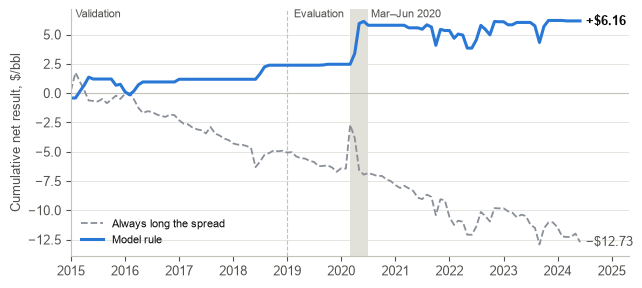

In [26]:
x = main_t.index.to_timestamp()
cum_main, cum_long = main_t["net"].cumsum(), long_t["net"].cumsum()
fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-06-30"), color="#e1e0d9", lw=0)
ax.axvline(pd.Timestamp("2019-01-01"), color="#c3c2b7", lw=0.8, ls="--")
ax.axhline(0, color="#c3c2b7", lw=0.8)
ax.plot(x, cum_long.values, color=GREY, lw=1.3, ls="--", label="Always long the spread")
ax.plot(x, cum_main.values, color=BLUE, lw=2.2, label="Model rule")
money = lambda v: ("+" if v >= 0 else "−") + f"${abs(v):.2f}"
ax.text(x[-1] + pd.Timedelta(days=40), cum_main.iloc[-1], money(cum_main.iloc[-1]), color=INK, fontsize=9, va="center", fontweight="bold")
ax.text(x[-1] + pd.Timedelta(days=40), cum_long.iloc[-1], money(cum_long.iloc[-1]), color=MUTED, fontsize=9, va="center")
top = ax.get_ylim()[1]
ax.text(pd.Timestamp("2020-07-20"), top, "Mar–Jun 2020", color=MUTED, fontsize=8, va="top")
ax.text(pd.Timestamp("2015-02-01"), top, "Validation", color=MUTED, fontsize=8, va="top")
ax.text(pd.Timestamp("2019-02-15"), top, "Evaluation", color=MUTED, fontsize=8, va="top", ha="left")
ax.set_ylabel("Cumulative net result, $/bbl")
ax.set_xlim(x[0], x[-1] + pd.Timedelta(days=330))
ax.legend(loc="lower left", fontsize=8)
ax.xaxis.set_major_locator(mdates.YearLocator(1)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
save(fig, "fig1_strategy_performance")
RESULTS["trading"] = {col: {k_: (v if isinstance(v, str) else float(v)) for k_, v in trade_table[col].items()} for col in trade_table}
RESULTS["trading_double_cost"] = {"all": net_double.sum(), "2015-18": net_double[is_val].sum(), "2019-24": net_double[~is_val].sum()}
RESULTS["trading_years_up"] = int((by_year > 0).sum()); RESULTS["trading_years"] = int(len(by_year))

In [27]:
# Save the key numbers quoted in the report
def plain(o):
    if isinstance(o, dict):
        return {str(k_): plain(v) for k_, v in o.items()}
    if isinstance(o, (np.floating, np.integer)):
        return float(o)
    return o

(OUT_DIR / "report_numbers.json").write_text(json.dumps(plain(RESULTS), indent=2))
print("Saved", len(list(FIG_DIR.glob('*.png'))), "figures to figures/ and", len(list(OUT_DIR.glob('*.csv'))), "tables to outputs/")

Saved 7 figures to figures/ and 20 tables to outputs/
